# 01 — Exploration des données

**Objectif** : connaître le jeu de données avant d'entraîner quoi que ce soit : combien d'images, quel
déséquilibre entre classes, à quoi ressemblent les radiographies, quelles tailles, et surtout **combien
d'images par patient** (pour éviter la fuite de données entre entraînement et validation).

**Données** : *Chest X-Ray Images (Pneumonia)*, Kaggle (P. Mooney), issu de Kermany D. et al.,
*Cell* 2018, 172(5):1122-1131 ; données d'origine sur Mendeley Data (CC BY 4.0),
doi:10.17632/rscbjbr9sj.3. Radiographies thoraciques **pédiatriques** (enfants de 1 à 5 ans,
Guangzhou Women and Children's Medical Center).

Téléchargement (depuis la racine du dépôt, avec `kaggle.json` configuré) :
```
kaggle datasets download -d paultimothymooney/chest-xray-pneumonia -p data/raw
```

In [1]:
import sys
from pathlib import Path

# Le notebook est dans notebooks/ : on remonte à la racine du dépôt pour importer src/
RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RACINE))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option("display.precision", 3)
%matplotlib inline
%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"dpi": 90, "bbox_inches": "tight"}
from PIL import Image
from src.data import (DOSSIER_DONNEES, DOSSIER_FIGURES, DOSSIER_RESULTATS, SEED, construire_cache,
                      decoupage_par_patient, extraire_archive, lister_images, verifier_fuite)
DOSSIER_FIGURES.mkdir(exist_ok=True); DOSSIER_RESULTATS.mkdir(exist_ok=True)
MARINE, GRIS = "#14284b", "#52514e"
COUL = {"NORMAL": "#1baf7a", "PNEUMONIA": "#6250d6"}

In [2]:
extraire_archive()          # n'extrait que chest_xray/{train,val,test} (l'archive contient un doublon)
df = lister_images()
print(len(df), "images")
df.head()

5856 images


,chemin,fichier,split_officiel,classe,label,patient,sous_type
0,train/NORMAL/IM-0115-0001.jpeg,IM-0115-0001.jpeg,train,NORMAL,0,IM-0115,normal
1,train/NORMAL/IM-0117-0001.jpeg,IM-0117-0001.jpeg,train,NORMAL,0,IM-0117,normal
2,train/NORMAL/IM-0119-0001.jpeg,IM-0119-0001.jpeg,train,NORMAL,0,IM-0119,normal
3,train/NORMAL/IM-0122-0001.jpeg,IM-0122-0001.jpeg,train,NORMAL,0,IM-0122,normal
4,train/NORMAL/IM-0125-0001.jpeg,IM-0125-0001.jpeg,train,NORMAL,0,IM-0125,normal


## 1. Combien d'images par classe et par split ?

In [3]:
comptes = df.groupby(["split_officiel", "classe"]).size().unstack().loc[["train", "val", "test"]]
comptes["total"] = comptes.sum(axis=1)
comptes["% pneumonie"] = (100 * comptes["PNEUMONIA"] / comptes["total"]).round(1)
comptes

classe,NORMAL,PNEUMONIA,total,% pneumonie
split_officiel,,,,
train,1341,3875,5216,74.3
val,8,8,16,50.0
test,234,390,624,62.5


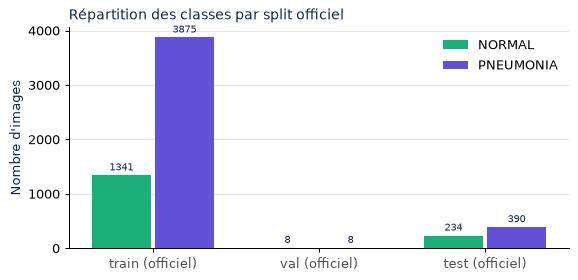

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 3.2), dpi=150)
splits = ["train", "val", "test"]
x = np.arange(len(splits))
for k, classe in enumerate(["NORMAL", "PNEUMONIA"]):
    vals = comptes.loc[splits, classe].to_numpy()
    barres = ax.bar(x + (k - 0.5) * 0.38, vals, width=0.36, color=COUL[classe], label=classe)
    ax.bar_label(barres, padding=2, fontsize=8, color=MARINE)
ax.set_xticks(x, ["train (officiel)", "val (officiel)", "test (officiel)"], color=GRIS)
ax.set_ylabel("Nombre d'images", color=MARINE)
ax.set_title("Répartition des classes par split officiel", loc="left", color=MARINE, fontsize=11)
for c in ["top", "right"]: ax.spines[c].set_visible(False)
ax.grid(axis="y", color="#e7e6e1"); ax.set_axisbelow(True)
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(DOSSIER_FIGURES / "repartition_classes.png", bbox_inches="tight")

### Observations
- **5 856 images** au total, comme annoncé par les auteurs.
- **Déséquilibre** : 74,3 % de pneumonies dans le train officiel (3 875 contre 1 341). Un modèle qui répondrait toujours « pneumonie » aurait déjà 74 % d'accuracy sur le train : l'accuracy seule est donc trompeuse. On utilisera une perte pondérée et des métriques médicales (sensibilité, spécificité, AUC).
- **Validation officielle de 16 images** (8 + 8) : beaucoup trop petite pour décider quoi que ce soit (une erreur = 6 points de pourcentage). On recrée une validation à partir du train.
- **Le test n'a pas la même proportion** que le train : 62,5 % de pneumonies au lieu de 74 %. Ce sera à garder en tête pour la précision et la VPN, qui dépendent de la prévalence.

## 2. À quoi ressemblent les radiographies ?

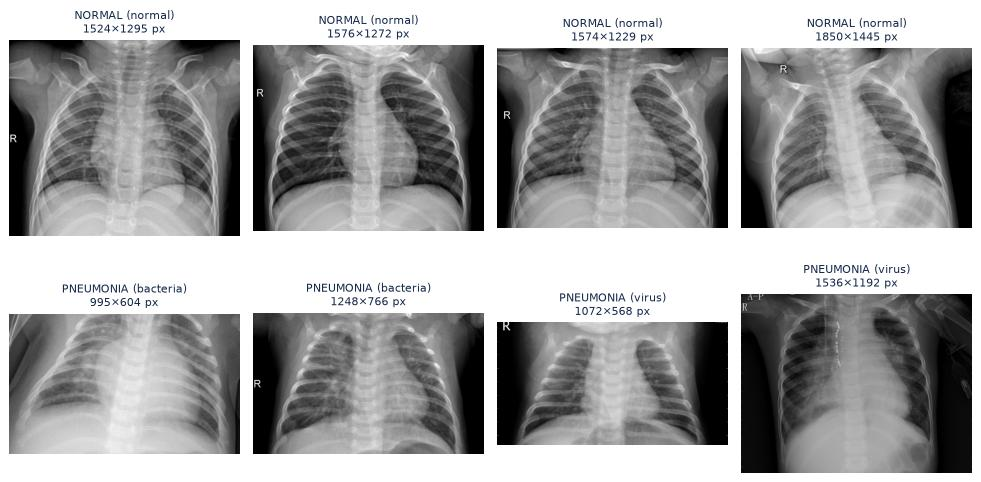

In [5]:
tirage = pd.concat([
    df[(df.split_officiel == "train") & (df.sous_type == "normal")].sample(4, random_state=SEED),
    df[(df.split_officiel == "train") & (df.sous_type == "bacteria")].sample(2, random_state=SEED),
    df[(df.split_officiel == "train") & (df.sous_type == "virus")].sample(2, random_state=SEED),
])
fig, axes = plt.subplots(2, 4, figsize=(11, 6), dpi=130)
for ax, (_, r) in zip(axes.ravel(), tirage.iterrows()):
    with Image.open(DOSSIER_DONNEES / r.chemin) as im:
        ax.imshow(im.convert("L"), cmap="gray")
        ax.set_title(f"{r.classe} ({r.sous_type})\n{im.size[0]}×{im.size[1]} px", fontsize=9, color=MARINE)
    ax.axis("off")
fig.tight_layout(); fig.savefig(DOSSIER_FIGURES / "exemples_radiographies.png", bbox_inches="tight")

### Observations
Les radiographies sont de face, d'enfants. On voit aussi des **éléments non médicaux** : lettre « R » (côté droit du patient), texte « A-P », câbles ou électrodes sur certaines images, et un cadrage variable (épaules et bras visibles ou non). Ce sont des **raccourcis potentiels** : un modèle pourrait les utiliser au lieu des poumons. On le vérifiera avec Grad-CAM.

## 3. Tailles des images

In [6]:
def taille(chemin):
    with Image.open(DOSSIER_DONNEES / chemin) as im:   # lit seulement l'en-tête, rapide
        return im.size, im.mode
infos = [taille(c) for c in df.chemin]
df["largeur"] = [s[0] for s, _ in infos]
df["hauteur"] = [s[1] for s, _ in infos]
df["mode"] = [m for _, m in infos]
df["ratio"] = df.largeur / df.hauteur
print(df["mode"].value_counts())
df.groupby("classe")[["largeur", "hauteur", "ratio"]].describe().T.round(2)

mode
L      5573
RGB     283
Name: count, dtype: int64


classe          NORMAL  PNEUMONIA
largeur count  1583.00    4273.00
        mean   1686.38    1195.07
        std     305.32     285.15
        min     912.00     384.00
        25%    1472.00    1000.00
        50%    1654.00    1160.00
        75%    1848.00    1360.00
        max    2916.00    2772.00
hauteur count  1583.00    4273.00
        mean   1378.65     819.55
        std     343.02     270.86
        min     496.00     127.00
        25%    1140.00     640.00
        50%    1323.00     776.00
        75%    1554.00     960.00
        max    2713.00    2304.00
ratio   count  1583.00    4273.00
        mean      1.25       1.51
        std       0.15       0.25
        min       0.88       0.84
        25%       1.15       1.36
        50%       1.23       1.49
        75%       1.34       1.65
        max       2.11       3.38

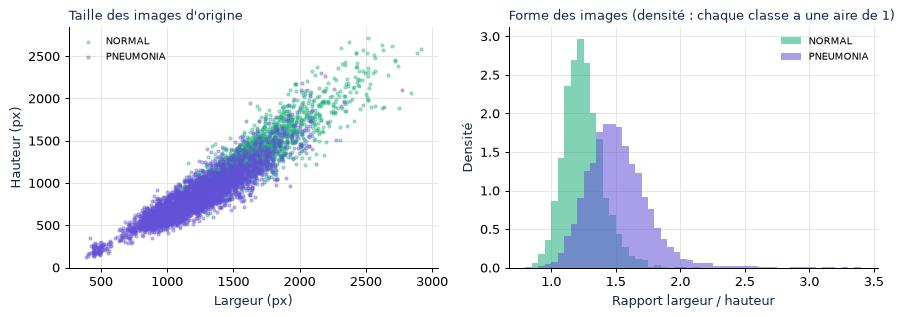

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), dpi=150)
for classe in ["NORMAL", "PNEUMONIA"]:
    s = df[df.classe == classe]
    axes[0].scatter(s.largeur, s.hauteur, s=6, alpha=0.35, color=COUL[classe], label=classe)
    axes[1].hist(s.ratio, bins=np.linspace(0.8, 3.4, 53), density=True, alpha=0.55, color=COUL[classe], label=classe)
axes[0].set_xlabel("Largeur (px)", color=MARINE); axes[0].set_ylabel("Hauteur (px)", color=MARINE)
axes[0].set_title("Taille des images d'origine", loc="left", color=MARINE, fontsize=10)
axes[1].set_xlabel("Rapport largeur / hauteur", color=MARINE); axes[1].set_ylabel("Densité", color=MARINE)
axes[1].set_title("Forme des images (densité : chaque classe a une aire de 1)", loc="left", color=MARINE, fontsize=10)
for ax in axes:
    for c in ["top", "right"]: ax.spines[c].set_visible(False)
    ax.grid(color="#e7e6e1"); ax.set_axisbelow(True); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(DOSSIER_FIGURES / "tailles_images.png", bbox_inches="tight")

### Un raccourci possible : la forme de l'image

Les pneumonies sont en moyenne plus **larges** que les normales. Question : la forme de l'image suffit-elle,
à elle seule, à « deviner » la classe ? On calcule l'AUC du seul rapport largeur/hauteur (sans regarder
l'image) :

In [8]:
from sklearn.metrics import roc_auc_score
for s in ["train", "test"]:
    d = df[df.split_officiel == s]
    print(f"{s:5s} : AUC du seul rapport largeur/hauteur = {roc_auc_score(d.label, d.ratio):.3f}")

train : AUC du seul rapport largeur/hauteur = 0.865
test  : AUC du seul rapport largeur/hauteur = 0.704


**Conséquence sur le prétraitement.** Si l'on écrase chaque image en carré 224×224, cette forme devient
une *déformation de l'anatomie* (un thorax large écrasé paraît étroit) : un raccourci facile pour un réseau.
On choisit donc le prétraitement standard d'ImageNet : **petit côté ramené à 224 px, puis recadrage
central 224×224**. Les proportions réelles sont conservées et la forme d'origine n'est plus visible.
Contrepartie : les bords latéraux des images très larges sont coupés (en général les bras et les épaules).

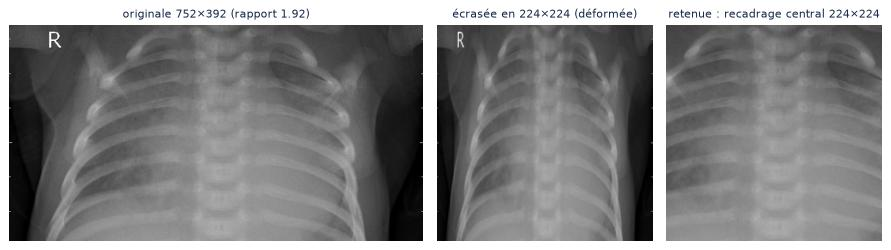

In [9]:
from src.data import redimensionner_recadrer
exemple = df[(df.classe == "PNEUMONIA") & (df.split_officiel == "train")].sort_values("ratio").iloc[-200]
with Image.open(DOSSIER_DONNEES / exemple.chemin) as im:
    orig = im.convert("L")
    ecrase = orig.resize((224, 224), Image.BILINEAR)
    recadre = redimensionner_recadrer(orig, 224)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), dpi=130, gridspec_kw={"width_ratios": [exemple.ratio, 1, 1]})
for ax, im, t in zip(axes, [orig, ecrase, recadre],
                     [f"originale {orig.size[0]}×{orig.size[1]} (rapport {exemple.ratio:.2f})",
                      "écrasée en 224×224 (déformée)", "retenue : recadrage central 224×224"]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255); ax.set_title(t, fontsize=9, color=MARINE); ax.axis("off")
fig.tight_layout(); fig.savefig(DOSSIER_FIGURES / "pretraitement.png", bbox_inches="tight")

### Observations
- 283 images sont en RVB et 5 573 en niveaux de gris : on convertit tout en niveaux de gris.
- Les tailles sont très variables (de 384 à 2 916 px de large).
- **Biais de forme** : les pneumonies sont nettement plus larges (rapport largeur/hauteur médian 1,49 contre 1,23 pour les normales). Ce rapport seul, sans regarder l'image, donne une **AUC de 0,865 sur le train** et de **0,704 sur le test**. C'est un indice d'acquisition (cadrage, appareil, période) et non un signe médical.
- D'où le choix du **recadrage central sans déformation**. Il ne supprime pas toutes les différences d'acquisition (contraste, cadrage, marqueurs), d'où l'analyse Grad-CAM de l'étape 4.

## 4. Identifiants patients

Les noms de fichiers contiennent un identifiant :
- pneumonies : `person1234_bacteria_5678.jpeg` → patient `person1234`, sous-type bactérienne/virale
  (variante rencontrée : `person447_virus_921_1.jpeg`) ;
- normales : `IM-0115-0001.jpeg` ou `NORMAL2-IM-1427-0001.jpeg` → patient `IM-0115` / `IM-1427`
  (variante : `IM-0429-0001-0002.jpeg`).

Le jeu de données ne documente pas ces noms : on fait donc des **hypothèses prudentes**.
On regroupe toutes les images qui *pourraient* venir du même enfant :
- `IM-0651` et `NORMAL2-IM-0651` → même groupe ;
- `person1_bacteria_…` et `person1_virus_…` → même groupe.

Regrouper à tort ne crée jamais de fuite (cela rend seulement le découpage un peu moins libre) ;
séparer à tort pourrait en créer. Dans la suite, « patient » désigne ce **groupe prudent**.

In [10]:
# Vérification : tous les noms de fichiers suivent-ils un motif connu ?
print("Noms non reconnus :", (df.sous_type == "inconnu").sum())
normales = df[df.classe == "NORMAL"].fichier
print("Normales avec préfixe NORMAL2 :", normales.str.startswith("NORMAL2").sum(), "/", len(normales))

Noms non reconnus : 0
Normales avec préfixe NORMAL2 : 917 / 1583


In [11]:
print("Sous-types :", df.sous_type.value_counts().to_dict())
par_patient = df[df.split_officiel != "test"].groupby(["classe", "patient"]).size().rename("n_images")
print("\nImages par patient (train + val officiels) :")
display(par_patient.groupby("classe").describe().round(2))
print("Patients avec plus d'une image :",
      (par_patient > 1).groupby("classe").sum().to_dict())

Sous-types : {'bacteria': 2780, 'normal': 1583, 'virus': 1493}

Images par patient (train + val officiels) :


,count,mean,std,min,25%,50%,75%,max
classe,,,,,,,,
NORMAL,1008.0,1.34,0.70,1.0,1.0,1.0,1.0,6.0
PNEUMONIA,1642.0,2.36,2.05,1.0,1.0,2.0,3.0,30.0


Patients avec plus d'une image : {'NORMAL': 244, 'PNEUMONIA': 1006}


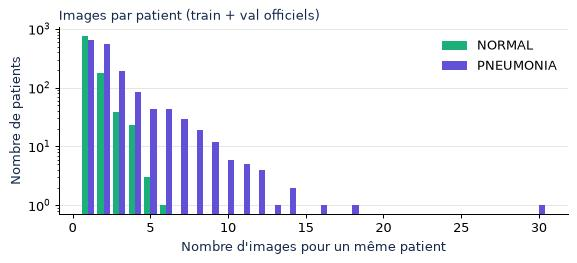

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 3), dpi=150)
for classe in ["NORMAL", "PNEUMONIA"]:
    v = par_patient.loc[classe].value_counts().sort_index()
    ax.bar(v.index + (0.2 if classe == "PNEUMONIA" else -0.2), v.values, width=0.4,
           color=COUL[classe], label=classe)
ax.set_xlabel("Nombre d'images pour un même patient", color=MARINE)
ax.set_ylabel("Nombre de patients", color=MARINE); ax.set_yscale("log")
ax.set_title("Images par patient (train + val officiels)", loc="left", color=MARINE, fontsize=10)
for c in ["top", "right"]: ax.spines[c].set_visible(False)
ax.grid(axis="y", color="#e7e6e1"); ax.set_axisbelow(True); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(DOSSIER_FIGURES / "images_par_patient.png", bbox_inches="tight")

In [13]:
# Un même identifiant person a-t-il des images bactériennes ET virales ?
pn = df[df.label == 1]
for s in ["train", "test"]:
    n = pn[pn.split_officiel == s].groupby("patient").sous_type.nunique()
    print(f"{s:5s} : identifiants avec les deux sous-types : {(n > 1).sum()} / {len(n)}")

train : identifiants avec les deux sous-types : 808 / 1635
test  : identifiants avec les deux sous-types : 1 / 202


In [14]:
# Les identifiants du test officiel recoupent-ils ceux du train officiel ?
ids = {s: set(df.loc[df.split_officiel == s, "patient"]) for s in ["train", "val", "test"]}
communs = ids["train"] & ids["test"]
print("Identifiants communs train officiel / test officiel :", len(communs),
      f"(dont {sum(p.startswith('person') for p in communs)} de pneumonie)")
print("Identifiants communs train officiel / val officiel  :", len(ids["train"] & ids["val"]))
# Pour les pneumonies communes : le sous-type est-il le même des deux côtés ?
st = {s: pn[pn.split_officiel == s].groupby("patient").sous_type.agg(lambda x: x.mode()[0]) for s in ["train", "test"]}
c = sorted(set(st["train"].index) & set(st["test"].index))
accord = np.mean([st["train"][i] == st["test"][i] for i in c])
hasard = (st["train"].value_counts(normalize=True) * st["test"].value_counts(normalize=True)).sum()
print(f"Même sous-type en train et en test : {accord:.0%} des cas (attendu si indépendant : {hasard:.0%})")

Identifiants communs train officiel / test officiel : 264 (dont 170 de pneumonie)
Identifiants communs train officiel / val officiel  : 0
Même sous-type en train et en test : 0% des cas (attendu si indépendant : 43%)


### Observations
- Tous les noms de fichiers suivent un motif connu (0 non reconnu).
- Groupes patients (prudents) dans train + val officiels : 1 008 pour les normales (1,34 image en moyenne, jusqu'à 6) et 1 642 pour les pneumonies (2,36 images en moyenne, **jusqu'à 30 images pour un même identifiant**). 1 006 groupes de pneumonie ont plusieurs images : le risque de fuite est réel.
- Dans le train, 808 identifiants `personX` sur 1 635 ont à la fois des images bactériennes et virales, contre 1 sur 202 dans le test. La numérotation est donc probablement propre à chaque sous-type. Notre regroupement par numéro reste prudent dans les deux hypothèses.
- **264 identifiants apparaissent à la fois dans le train et le test officiels**, mais pour les 170 identifiants de pneumonie communs, le sous-type est *toujours* différent (0 % d'accord contre 43 % attendus si c'étaient les mêmes enfants). La numérotation semble donc indépendante entre les splits officiels : ce ne sont probablement pas les mêmes enfants. **On ne peut pas le vérifier.** On garde le test officiel intact (protocole standard) et on le signale comme limite.

## 5. Pourquoi découper par patient ?

Si on tire la validation **image par image**, les radiographies d'un même enfant peuvent se retrouver à
la fois en entraînement et en validation. Le modèle peut alors reconnaître *l'enfant* (morphologie,
positionnement, appareil) plutôt que *la maladie*, et la validation devient trop optimiste.
On le vérifie d'abord avec un découpage naïf :

In [15]:
from sklearn.model_selection import train_test_split
pool = df[df.split_officiel != "test"]
tr, va = train_test_split(pool, test_size=1/7, stratify=pool.label, random_state=SEED)
commun = set(tr.patient) & set(va.patient)
print(f"Découpage naïf (par image) : {len(commun)} patients à la fois en train et en validation, "
      f"soit {va.patient.isin(commun).sum()} images de validation sur {len(va)} "
      f"({va.patient.isin(commun).mean():.0%}) dont l'enfant a aussi des images en train.")

Découpage naïf (par image) : 428 patients à la fois en train et en validation, soit 532 images de validation sur 748 (71%) dont l'enfant a aussi des images en train.


In [16]:
# Découpage retenu : StratifiedGroupKFold (groupes = patients, stratification = classe), 1 pli sur 7
df = decoupage_par_patient(df)
nouveau = df.groupby(["split", "classe"]).size().unstack().loc[["train", "val", "test"]]
nouveau["% pneumonie"] = (100 * nouveau.PNEUMONIA / nouveau.sum(axis=1)).round(1)
nouveau["patients"] = df.groupby("split").patient.nunique()
display(nouveau)
print("Patients partagés :", verifier_fuite(df))

classe,NORMAL,PNEUMONIA,% pneumonie,patients
split,,,,
train,1156,3328,74.2,2271
val,193,555,74.2,379
test,234,390,62.5,404


Patients partagés : {'train∩val': 0, 'train∩test': 219, 'val∩test': 45}


In [17]:
# Sauvegarde du découpage (reproductibilité) et du cache d'images 224x224
# (petit côté à 224 px puis recadrage central : voir la section 3)
colonnes = ["chemin", "fichier", "split_officiel", "split", "classe", "label", "patient", "sous_type"]
df[colonnes].to_csv(DOSSIER_RESULTATS / "split.csv", index=False)
cache = construire_cache(df[colonnes])
print("Cache :", cache.shape, cache.dtype, f"{cache.nbytes / 1e6:.0f} Mo")

Cache : (5856, 224, 224) uint8 294 Mo


### Conclusion de l'exploration
- **Découpage retenu** : train 4 484 images (2 271 groupes), validation 748 images (379 groupes), test officiel 624 images. Même proportion de pneumonies en train et en validation (74,2 %).
- **0 patient commun entre train et validation**. Un découpage naïf, image par image, aurait mis 428 patients des deux côtés : 71 % des images de validation auraient eu « leur » enfant dans le train, et la validation aurait été trop optimiste.
- Le **test officiel** reste intact et ne servira qu'à l'évaluation finale.
- **Prétraitement** : niveaux de gris, petit côté à 224 px, recadrage central 224×224 (pas de déformation), puis 3 canaux et normalisation ImageNet au moment de l'entraînement.
- **Points de vigilance pour la suite** : déséquilibre des classes, biais de forme d'image, éléments non médicaux (marqueurs, câbles), prévalence différente entre validation (74 %) et test (62,5 %).